In [5]:
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
import matplotlib
print("Alles funktioniert!")



Alles funktioniert!


In [6]:
train_data = pd.read_csv('data/train.csv')
test_data = pd.read_csv('data/test.csv')

train_data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


<Axes: xlabel='Age', ylabel='Fare'>

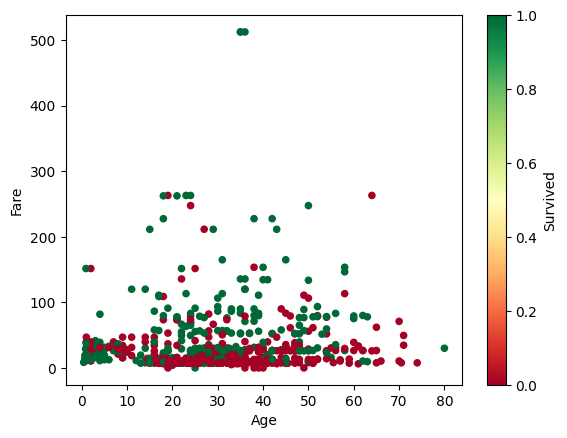

In [7]:
train_data.plot.scatter(x="Age", y="Fare", c="Survived", colormap="RdYlGn")

In [8]:
y = train_data["Survived"]

train_data["Embarked"] = train_data["Embarked"].fillna('S')
imp = SimpleImputer(missing_values=np.nan, strategy="mean")
train_data["Age"] = imp.fit_transform(train_data[["Age"]])

features = ["Pclass", "Sex", "SibSp", "Parch"]


In [9]:
X = pd.get_dummies(train_data[features])
test_features = pd.get_dummies(test_data[features])

In [10]:
model = DecisionTreeClassifier()
model.fit(X, y)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [11]:
submission = model.predict(test_features)

output = pd.DataFrame({
    "PassengerId": test_data.PassengerId,
    "Survived": submission})
output.to_csv('submission.csv', index=False)
output = pd.DataFrame({"PassengerId": test_data.PassengerId, "Survived": submission})
output.head()

,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,0
